(c) Measure PRCs numerically by direct perturbation: at phase φ kick the voltage by a small δ (say 10−3), record the time T 0 of the next spike, and compute R(φ) ≈ (∆ − T0)/(∆δ), repeating on a grid of φ. First do this for the LIF of part (a) with τ = 1, vr = 0, vth = 1, I = 1.5, and overlay your formula. Then do it for the FitzHugh–Nagumo oscillator dv dt = v − v3/3 − w + 0.5 dw, dt = 0.08 (v + 0.7 − 0.8w), kicking v, with phase zero at the upward crossing of v = 0. Here there is no reset, so measure the shift in a crossing a few cycles later, after the perturbation has relaxed back to the limit cycle. Report the period, the extreme values of R, and where R < 0. Which PRC is Type I and which is Type II, and what does a negative lobe mean physically?

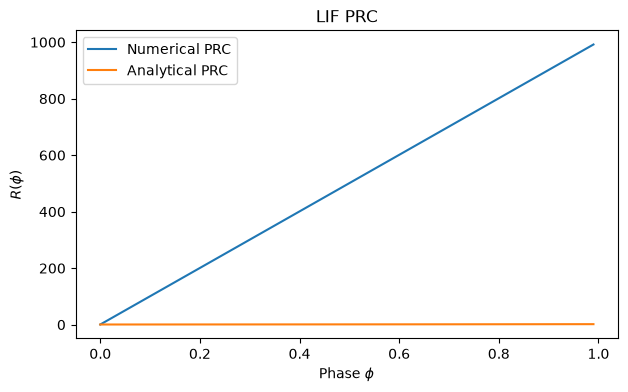

Lif period = 1.0986
LIF numerical PRC range = [0.6070, 991.8024]


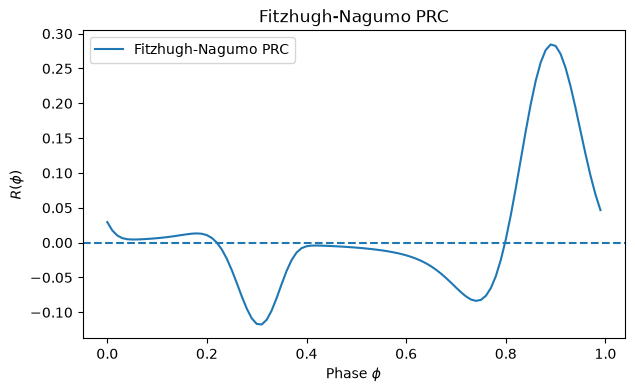


Fitzhugh-Nagumo period = 39.4744
Fitzhugh-Nagumo minimum R = -0.1175
Fitzhugh-Nagumo maximum R = 0.2845
R < 0 for: 0.2200 < phi < 0.7900


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# LIF
tau = 1.0
vr = 0.0
vth = 1.0
I = 1.5

delta_lif = tau * np.log((I - vr) / (I - vth))

def lif_v(t):
    return I + (vr - I) * np.exp(-t / tau)
    
def lif_prc(phi):
    v = lif_v(phi * delta_lif)
    return tau / (delta_lif * (I - v)) 

def lif_next_spike(v, delta):
    return tau * np.log((I - v - delta) / (I - vth))

# perturbation
delta = 1e-3    #"small kick"
phi_vals = np.linspace(0, 1, 100, endpoint = False)

R_lif = []
for phi in phi_vals: 
    t = phi * delta_lif
    v = lif_v(t)
    T0 = lif_next_spike(v, delta)
    R = (delta_lif - T0) / (delta_lif * delta)
    R_lif.append(R)

R_lif = np.array(R_lif)

# plot LIF PRC
plt.figure(figsize = (7, 4))
plt.plot(phi_vals, R_lif, label = "Numerical PRC")
plt.plot(phi_vals, lif_prc(phi_vals), label = "Analytical PRC")
plt.xlabel(r"Phase $\phi$")
plt.ylabel(r"$R(\phi)$")
plt.title("LIF PRC")
plt.legend()
plt.show()

# print data
print(f"Lif period = {delta_lif:.4f}")
print(f"LIF numerical PRC range = [{R_lif.min():.4f}, {R_lif.max():.4f}]") #    The extreme values for R


# Fitzhugh-Nagumo Oscillators
def fn_rhs(t, y):
    v, w = y
    return [
        v - (v**3 / 3) - w + 0.5,
        0.08 * (v + 0.7 - (0.8 * w))
    ]

# Upward crossing v = 0
def upward_crossing(t, y):
    return y[0]

upward_crossing.direction = 1
upward_crossing.terminal = False

# solve for limit cycle
sol = solve_ivp(
    fn_rhs, 
    [0, 2000],
    [0.0, 0.0], 
    events = upward_crossing, 
    rtol = 1e-9,
    atol = 1e-11, 
    max_step = 0.1,
    dense_output = True
)

crossings = sol.t_events[0]

t_start = crossings[-2]
t_end = crossings[-1]
delta_fn = t_end - t_start
y_start = sol.sol(t_start)

cycle = solve_ivp(
    fn_rhs, 
    [0, delta_fn], 
    y_start, 
    rtol = 1e-9,
    atol = 1e-11, 
    max_step = 0.1,
    dense_output = True
)

# perturb Fitzhugh nagumo
delta = 1e-3
num_cycles = 5
phi_vals_fn = np.linspace(0, 1, 100, endpoint = False)
R_fn = [] 

for phi in phi_vals_fn:
    t_kick = phi * delta_fn
    y_kick = cycle.sol(t_kick).copy()
    y_kick[0] += delta 

    perturb = solve_ivp(
        fn_rhs, 
        [t_kick, t_kick + (num_cycles + 1) * delta_fn], 
        y_kick, 
        events = upward_crossing,
        rtol = 1e-9,
        atol = 1e-11,
        max_step = 0.1,
    )

    # cross time after kick
    cross_time = perturb.t_events[0][num_cycles - 1]

    # shift in crossing  
    shift = cross_time - num_cycles * delta_fn

    R = -shift / (delta_fn * delta) 
    R_fn.append(R)

R_fn = np.array(R_fn)

# Plot Fitzhugh nagumo oscillators
plt.figure(figsize = (7, 4))
plt.plot(phi_vals_fn, R_fn, label = "Fitzhugh-Nagumo PRC")
plt.axhline(0, linestyle = "--")
plt.xlabel(r"Phase $\phi$")
plt.ylabel(r"$R(\phi)$")
plt.title("Fitzhugh-Nagumo PRC")
plt.legend()
plt.show()

# print data
print(f"\nFitzhugh-Nagumo period = {delta_fn:.4f}")
print(f"Fitzhugh-Nagumo minimum R = {R_fn.min():.4f}")
print(f"Fitzhugh-Nagumo maximum R = {R_fn.max():.4f}")

# filter out the negative R values
negative = phi_vals_fn[R_fn < 0]
if len(negative) > 0:
    print(f"R < 0 for: "  f"{negative.min():.4f} < phi < {negative.max():.4f}")
else: 
    print("R < 0 for no sampled values of phi")